In [44]:
import torch
import pandas as pd
import numpy as np
from glob import glob
import os
from unet import UNet
import torch
from segment_net_main import global_brain_eval, predict_brain, predict_numpy_brain
import pandas as pd
import numpy as np

from nilearn.plotting import plot_anat
from matplotlib.patches import Rectangle
import ants
import matplotlib.pyplot as plt
from skimage import measure
from matplotlib import gridspec

meta = pd.read_csv('results/bids_head1.csv')

def get_crop(mat):
    """ find first slice with non-zero voxels in each dimension borrow from NeBSS"""
    for i in range(mat.shape[0]):
        xmin = i
        if np.sum(mat[i, :, :]) > 0:
                break
    for i in range(mat.shape[0]-1, 0, -1):
        xmax = i
        if np.sum(mat[i, :, :]) > 0:
                break
    for i in range(mat.shape[1]):
        ymin = i
        if np.sum(mat[:, i, :]) > 0:
                break
    for i in range(mat.shape[1]-1, 0, -1):
        ymax = i
        if np.sum(mat[:, i, :]) > 0:
                break
    for i in range(mat.shape[2]):
        zmin = i
        if np.sum(mat[:, :, i]) > 0:
                break
    for i in range(mat.shape[2]-1, 0, -1):
        zmax = i
        if np.sum(mat[:, :, i]) > 0:
                break
    return xmin,xmax,ymin,ymax,zmin,zmax

def modify_axis(ax):
    ax.axis('image')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_yticklabels([])
    ax.set_xticklabels([])
import seaborn as sns
from matplotlib.backends.backend_pdf import PdfPages

sns.set("paper", font_scale=2)
sns.set_style("ticks", {"xtick.major.size": 0,
                        "ytick.major.size": 0,
                        'font.family': ['sans-serif']})
import matplotlib.pyplot as plt
plt.rc(group={'font': {'size': 'larger'}})
%matplotlib inline

# Patch size equal 64

In [45]:
stat_tests = []
for sdf in glob('unets_models/*csv'):
    seed = os.path.basename(sdf).split('_')[5]
    epoch_df = pd.read_csv(sdf, index_col=0)
    epoch_df.loc[:, 'detection'] = epoch_df.dice > 0
    epoch_df_stat = epoch_df.groupby(['split', 'epoch']).apply(np.mean)
    stat_test = epoch_df_stat.loc['test', :]
    stat_test.loc[:, 'split'] = 'test'
    stat_test.loc[:, 'seed'] = seed
    stat_tests.append(stat_test)
    
    stat_test = epoch_df_stat.loc['valid', :]
    stat_test.loc[:, 'split'] = 'valid'
    stat_test.loc[:, 'seed'] = seed
    stat_tests.append(stat_test)
    
    stat_test = epoch_df_stat.loc['train', :]
    stat_test.loc[:, 'split'] = 'train'
    stat_test.loc[:, 'seed'] = seed
    stat_tests.append(stat_test)   
stat_tests = pd.concat(stat_tests, axis=0)
stat_tests.index = np.arange(stat_tests.shape[0])

In [46]:
stat_tests.head()

,iou,dice,epoch,detection,split,seed
0,0.000000,0.000000,1.0,0.0,test,999
1,0.000000,0.000000,2.0,0.0,test,999
2,0.270598,0.384093,3.0,0.8,test,999
3,0.282323,0.398010,4.0,0.8,test,999
4,0.351681,0.468899,5.0,0.8,test,999


## Select the best model by mean dice coefficients

In [47]:
stat_tests_casts = []
for i in np.unique(stat_tests.seed):
    stat_tests_cast = stat_tests.loc[stat_tests.seed==i,].pivot(index='epoch',
                                                                    columns='split', 
                                                                    values=['dice'])

    stat_tests_cast.columns = ['test', 'train', 'valid']
    stat_tests_cast.loc[:, 'seed'] = i
    stat_tests_casts.append(stat_tests_cast)
stat_tests_casts = pd.concat(stat_tests_casts)
stat_tests_casts = stat_tests_casts.sort_values(['valid', 'train'], ascending=False)

In [48]:
stat_tests_casts.loc[(stat_tests_casts.iloc[:, :3]>=0.6).apply(all, axis=1), :]

,test,train,valid,seed
epoch,,,,
25.0,0.606094,0.726194,0.759687,666
24.0,0.616183,0.743821,0.755063,666
18.0,0.607988,0.707349,0.754813,666
16.0,0.622053,0.658187,0.748643,666
23.0,0.643373,0.736915,0.738216,99999
29.0,0.607610,0.731292,0.735113,666
26.0,0.769066,0.722534,0.730828,555
9.0,0.610978,0.652488,0.724843,666
17.0,0.643281,0.675172,0.716329,99999


In [49]:
stat_tests_casts.loc[(stat_tests_casts.iloc[:, :3]>=0.7).apply(all, axis=1), :]

,test,train,valid,seed
epoch,,,,
26.0,0.769066,0.722534,0.730828,555


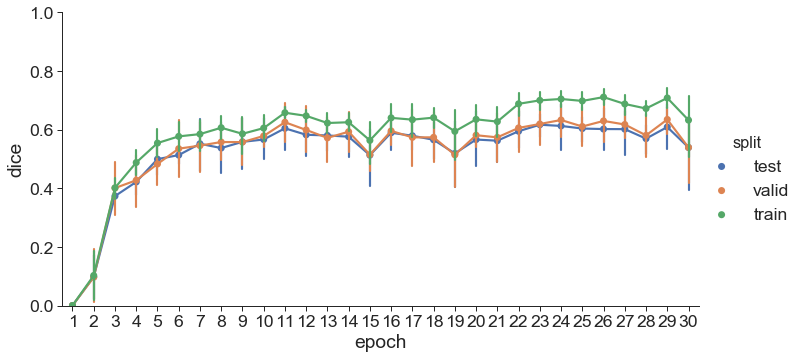

In [50]:
stat_tests.loc[:, 'epoch'] = stat_tests.loc[:, 'epoch'].astype('int')
results = sns.catplot(x='epoch', y='dice', alpha=0.7,  #col='split',
            kind='point', ci=90, n_boot=1000, hue='split', title="Dice coefficient across epochs",
            data=stat_tests, aspect=2)
plt.ylim(0, 1)
plt.savefig('results/Fig5_1.pdf')

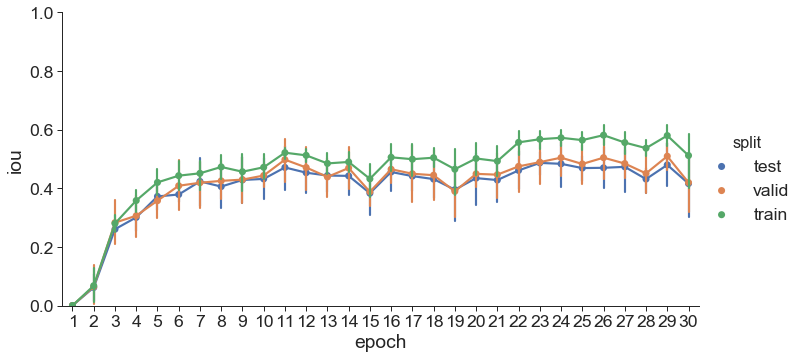

In [51]:
stat_tests.loc[:, 'epoch'] = stat_tests.loc[:, 'epoch'].astype('int')
results = sns.catplot(x='epoch', y='iou', alpha=0.7,  #col='split',
            kind='point', ci=90, n_boot=1000, hue='split', title="Dice coefficient across epochs",
            data=stat_tests, aspect=2)
plt.ylim(0, 1)

plt.savefig('results/Fig5_2.pdf')

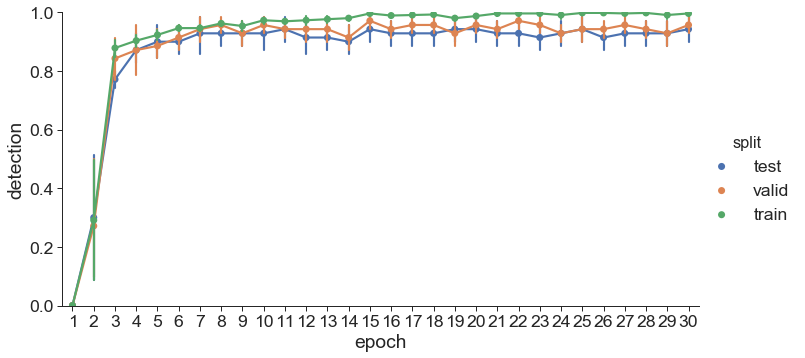

In [52]:
stat_tests.loc[:, 'epoch'] = stat_tests.loc[:, 'epoch'].astype('int')
results = sns.catplot(x='epoch', y='detection', alpha=0.7,  #col='split',
            kind='point', ci=90, n_boot=1000, hue='split', title="Dice coefficient across epochs",
            data=stat_tests, aspect=2)
plt.ylim(0, 1)

plt.savefig('results/Fig5_3.pdf')

## Balance positive and negative voxels


In [53]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
net = UNet(n_channels=1, n_classes=1).to('cuda')
test = pd.read_csv('results/test_low_555.csv', index_col=0)

## best model seed 555 epoch 26
for param in glob('unets_models/*epoch*26*seed_555_*pth'):
    net.load_state_dict(torch.load(param))
    net.eval()
    dices1, ious = global_brain_eval(net, test, list(range(test.shape[0])), 64)
    print(param, np.mean(dices1))
    break

unets_models/unet_batch_gen_epoch26_seed_555_patch_64.pth 0.7690664947032928


In [66]:
stat_tests.loc[(stat_tests.seed=='555') & (stat_tests.split=='test'), :]

,iou,dice,epoch,detection,split,seed
180,0.000000,0.000000,1,0.0,test,555
181,0.098606,0.160134,2,0.6,test,555
182,0.279474,0.403975,3,0.8,test,555
183,0.328532,0.465615,4,1.0,test,555
184,0.395523,0.550349,5,1.0,test,555
185,0.430564,0.580714,6,1.0,test,555
186,0.422014,0.567030,7,1.0,test,555
187,0.438959,0.595979,8,1.0,test,555
188,0.462053,0.612616,9,1.0,test,555
189,0.487413,0.647590,10,1.0,test,555


In [54]:
valid = pd.read_csv('results/valid_low_555.csv', index_col=0)
train =  pd.read_csv('results/train_low_555.csv', index_col=0)
print(np.max(train.patient), np.max(valid.patient))

161 145


In [55]:
meta.iloc[:100, 0].max()

161

In [56]:
match_id_dict = {}
for ii, t2f in zip(meta.iloc[:, 0], meta.loc[(meta.loc[:, 'pvl.label'] == '1-3'), :].t2f):
    match_id_dict[ii] = t2f

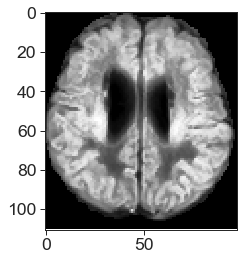

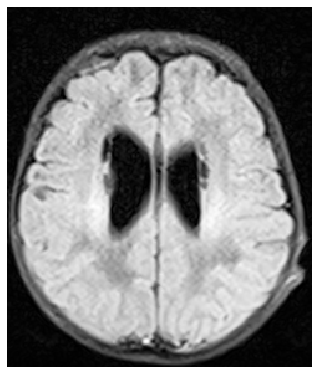

In [57]:
import ants
img = ants.image_read(match_id_dict[88])
plt.imshow(np.rot90(np.load(train.loc[train.patient==88, :].image.values[0])[:, :, 13][::-1, :]), 
           cmap=plt.cm.gray)
img.crop_image(img.get_mask()).plot(axis=2, figsize=5, slices=[13])

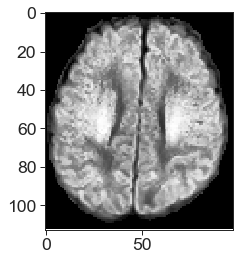

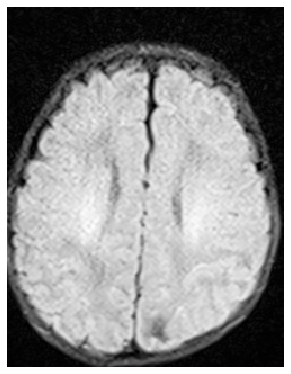

In [58]:
img = ants.image_read(match_id_dict[25])
plt.imshow(np.rot90(np.load(train.loc[train.patient==25, :].image.values[0])[:, :, 13][::-1, :]), 
           cmap=plt.cm.gray)
img.crop_image(img.get_mask()).plot(axis=2, figsize=5, slices=[13])

tensor(0.7027) tensor(13) tensor(19) tensor(18) tensor(37)


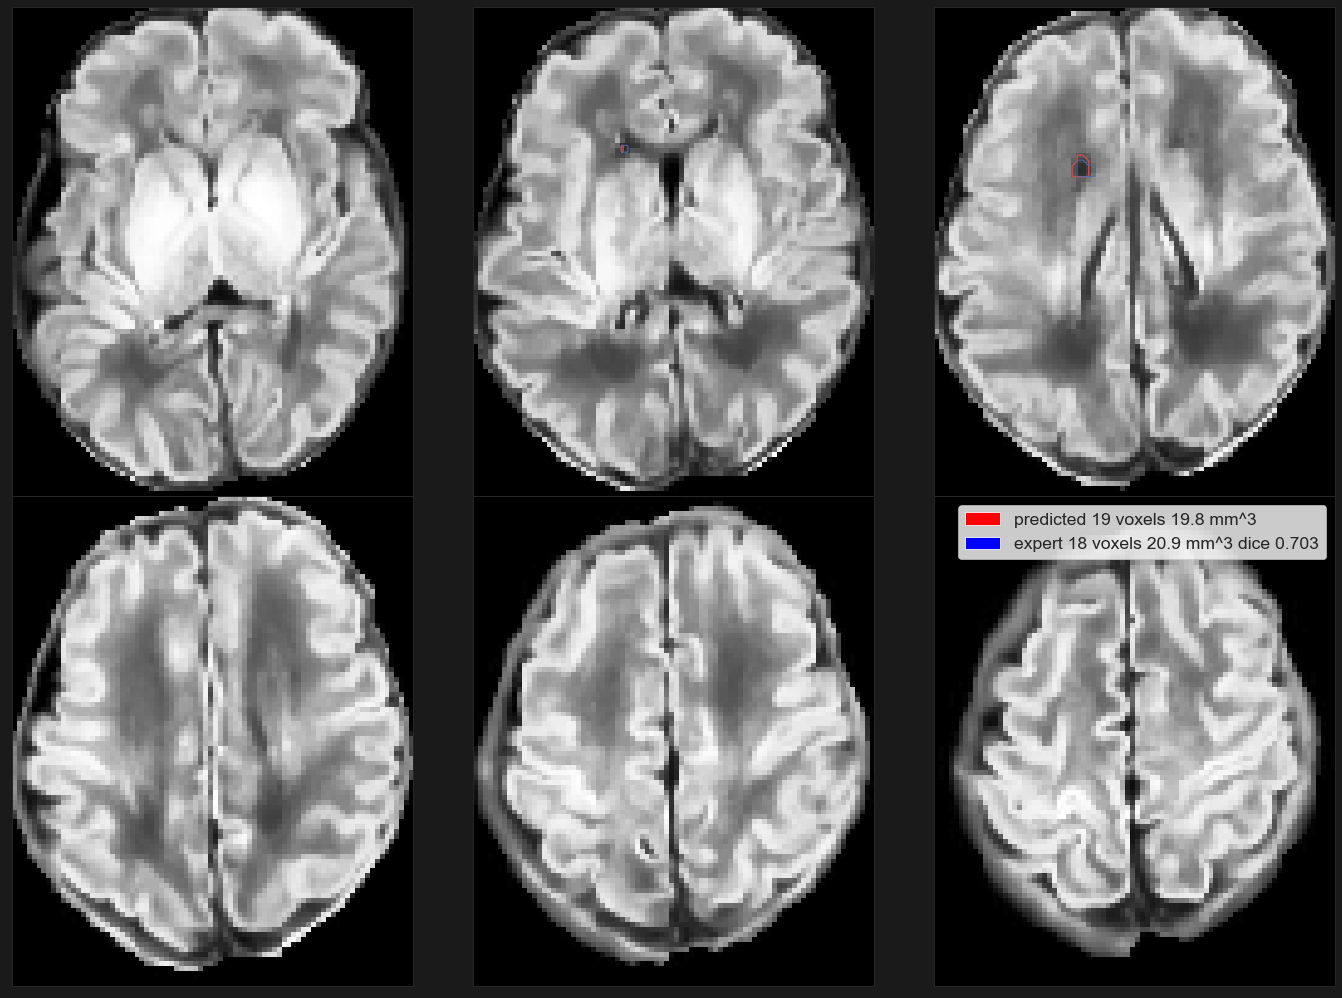

In [59]:
        img, mask, label = predict_brain(test, 0, net, 64)    
        spacing= np.prod(ants.get_spacing(ants.image_read(match_id_dict[test.iloc[0, :].patient])))
        t2f = img
        t2f_mask1 = (mask > 0.5).cpu()
        t2f_mask2 = label.cpu()
       
        ncol, nrow = 2, 3
        fig = plt.figure(figsize=((ncol-0.4)*12, (nrow+0.4)*4), facecolor='k')
        gs = gridspec.GridSpec(ncol, nrow, wspace=0, hspace=0, top=1, bottom=0, left=0, right=1)
        n = 8
        for i in range(ncol):
            for j in range(nrow):
                ax = plt.subplot(gs[i, j])
                ax.set_aspect("equal") # default equal
                ax.imshow(np.rot90(t2f[:, :, n])[:, ::-1], interpolation='nearest', cmap=plt.cm.gray)
                contours0 = measure.find_contours(np.rot90(t2f_mask1[:, :, n]==1)[:, ::-1], 0.8)
                for _, contour in enumerate(contours0):
                    ax.plot(contour[:, 1], contour[:, 0], linewidth=1.5, color='r')

                contours2 = measure.find_contours(np.rot90(t2f_mask2[:, :, n]==1)[:,::-1], 0.8)
                for _, contour in enumerate(contours2):
                    ax.plot(contour[:, 1], contour[:, 0], linewidth=1, color='b')
                modify_axis(ax)
                n += 1
        p_v = Rectangle((1, 1), 1.5, 1.5, fc="red")
        p_h = Rectangle((1, 1), 1.5, 1.5, fc="blue")
        v1 = (t2f_mask1>0).sum()
        v2 = (t2f_mask2>0).sum()
        dice = 2.0 * (t2f_mask1 * t2f_mask2).sum().float() / (v1+v2)
        print(dice, (t2f_mask1*t2f_mask2).sum(),v1, v2, v1+v2)
        plt.legend([p_v, p_h], ["predicted %s voxels %s mm^3" % (v1.item(), round(spacing*v2.item(),1)),
                                "expert %s voxels %s mm^3 dice %s" % (v2.item(), round(spacing*v1.item(),1),
                                                                      round(dice.item(), 3))],
                  loc='upper right', bbox_to_anchor=(1, 1))

tensor(0.6121) tensor(101) tensor(130) tensor(200) tensor(330)


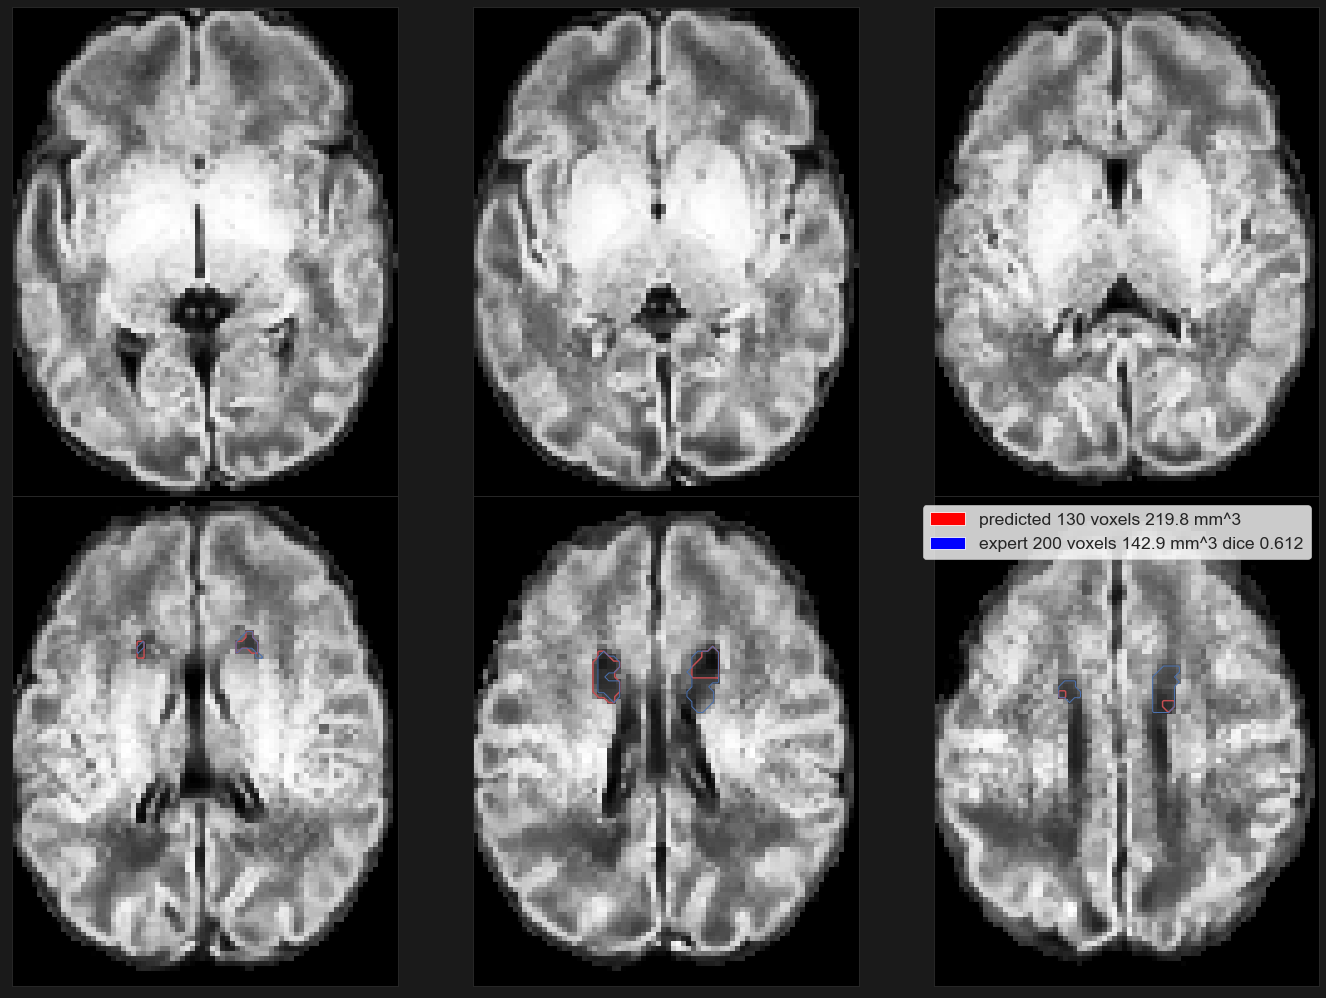

In [20]:
        img, mask, label = predict_brain(test, 6, net, 64)    
        spacing= np.prod(ants.get_spacing(ants.image_read(match_id_dict[test.iloc[0, :].patient])))
        t2f = img
        t2f_mask1 = (mask > 0.5).cpu()
        t2f_mask2 = label.cpu()
       
        ncol, nrow = 2, 3
        fig = plt.figure(figsize=((ncol-0.4)*12, (nrow+0.4)*4), facecolor='k')
        gs = gridspec.GridSpec(ncol, nrow, wspace=0, hspace=0, top=1, bottom=0, left=0, right=1)
        n = 8
        for i in range(ncol):
            for j in range(nrow):
                ax = plt.subplot(gs[i, j])
                ax.set_aspect("equal") # default equal
                ax.imshow(np.rot90(t2f[:, :, n])[:, ::-1], interpolation='nearest', cmap=plt.cm.gray)
                contours0 = measure.find_contours(np.rot90(t2f_mask1[:, :, n]==1)[:, ::-1], 0.8)
                for _, contour in enumerate(contours0):
                    ax.plot(contour[:, 1], contour[:, 0], linewidth=1.5, color='r')

                contours2 = measure.find_contours(np.rot90(t2f_mask2[:, :, n]==1)[:,::-1], 0.8)
                for _, contour in enumerate(contours2):
                    ax.plot(contour[:, 1], contour[:, 0], linewidth=1, color='b')
                modify_axis(ax)
                n += 1
        p_v = Rectangle((1, 1), 1.5, 1.5, fc="red")
        p_h = Rectangle((1, 1), 1.5, 1.5, fc="blue")
        v1 = (t2f_mask1>0).sum()
        v2 = (t2f_mask2>0).sum()
        dice = 2.0 * (t2f_mask1 * t2f_mask2).sum().float() / (v1+v2)
        print(dice, (t2f_mask1*t2f_mask2).sum(),v1, v2, v1+v2)
        plt.legend([p_v, p_h], ["predicted %s voxels %s mm^3" % (v1.item(), round(spacing*v2.item(),1)),
                                "expert %s voxels %s mm^3 dice %s" % (v2.item(), round(spacing*v1.item(),1),
                                                                      round(dice.item(), 3))],
                  loc='upper right', bbox_to_anchor=(1, 1))

tensor(0.8261) tensor(57) tensor(57) tensor(81) tensor(138)


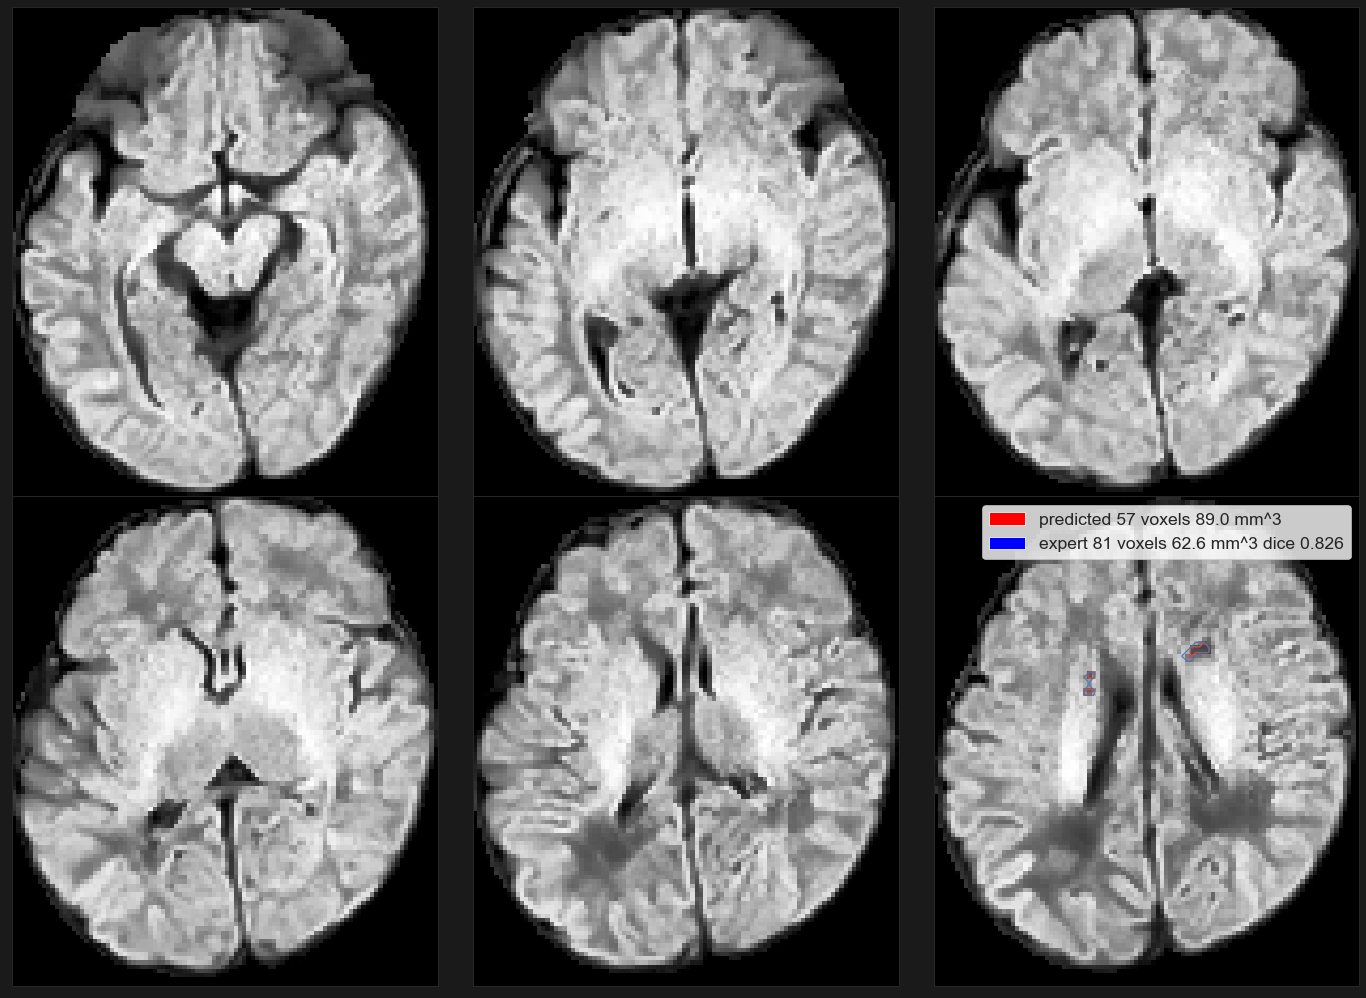

In [21]:
        img, mask, label = predict_brain(test, 7, net, 64)    
        spacing= np.prod(ants.get_spacing(ants.image_read(match_id_dict[test.iloc[0, :].patient])))
        t2f = img
        t2f_mask1 = (mask > 0.5).cpu()
        t2f_mask2 = label.cpu()
       
        ncol, nrow = 2, 3
        fig = plt.figure(figsize=((ncol-0.4)*12, (nrow+0.4)*4), facecolor='k')
        gs = gridspec.GridSpec(ncol, nrow, wspace=0, hspace=0, top=1, bottom=0, left=0, right=1)
        n = 8
        for i in range(ncol):
            for j in range(nrow):
                ax = plt.subplot(gs[i, j])
                ax.set_aspect("equal") # default equal
                ax.imshow(np.rot90(t2f[:, :, n])[:, ::-1], interpolation='nearest', cmap=plt.cm.gray)
                contours0 = measure.find_contours(np.rot90(t2f_mask1[:, :, n]==1)[:, ::-1], 0.8)
                for _, contour in enumerate(contours0):
                    ax.plot(contour[:, 1], contour[:, 0], linewidth=1.5, color='r')

                contours2 = measure.find_contours(np.rot90(t2f_mask2[:, :, n]==1)[:,::-1], 0.8)
                for _, contour in enumerate(contours2):
                    ax.plot(contour[:, 1], contour[:, 0], linewidth=1, color='b')
                modify_axis(ax)
                n += 1
        p_v = Rectangle((1, 1), 1.5, 1.5, fc="red")
        p_h = Rectangle((1, 1), 1.5, 1.5, fc="blue")
        v1 = (t2f_mask1>0).sum()
        v2 = (t2f_mask2>0).sum()
        dice = 2.0 * (t2f_mask1 * t2f_mask2).sum().float() / (v1+v2)
        print(dice, (t2f_mask1*t2f_mask2).sum(),v1, v2, v1+v2)
        plt.legend([p_v, p_h], ["predicted %s voxels %s mm^3" % (v1.item(), round(spacing*v2.item(),1)),
                                "expert %s voxels %s mm^3 dice %s" % (v2.item(), round(spacing*v1.item(),1),
                                                                      round(dice.item(), 3))],
                  loc='upper right', bbox_to_anchor=(1, 1))

tensor(0.8889) tensor(36) tensor(42) tensor(39) tensor(81)


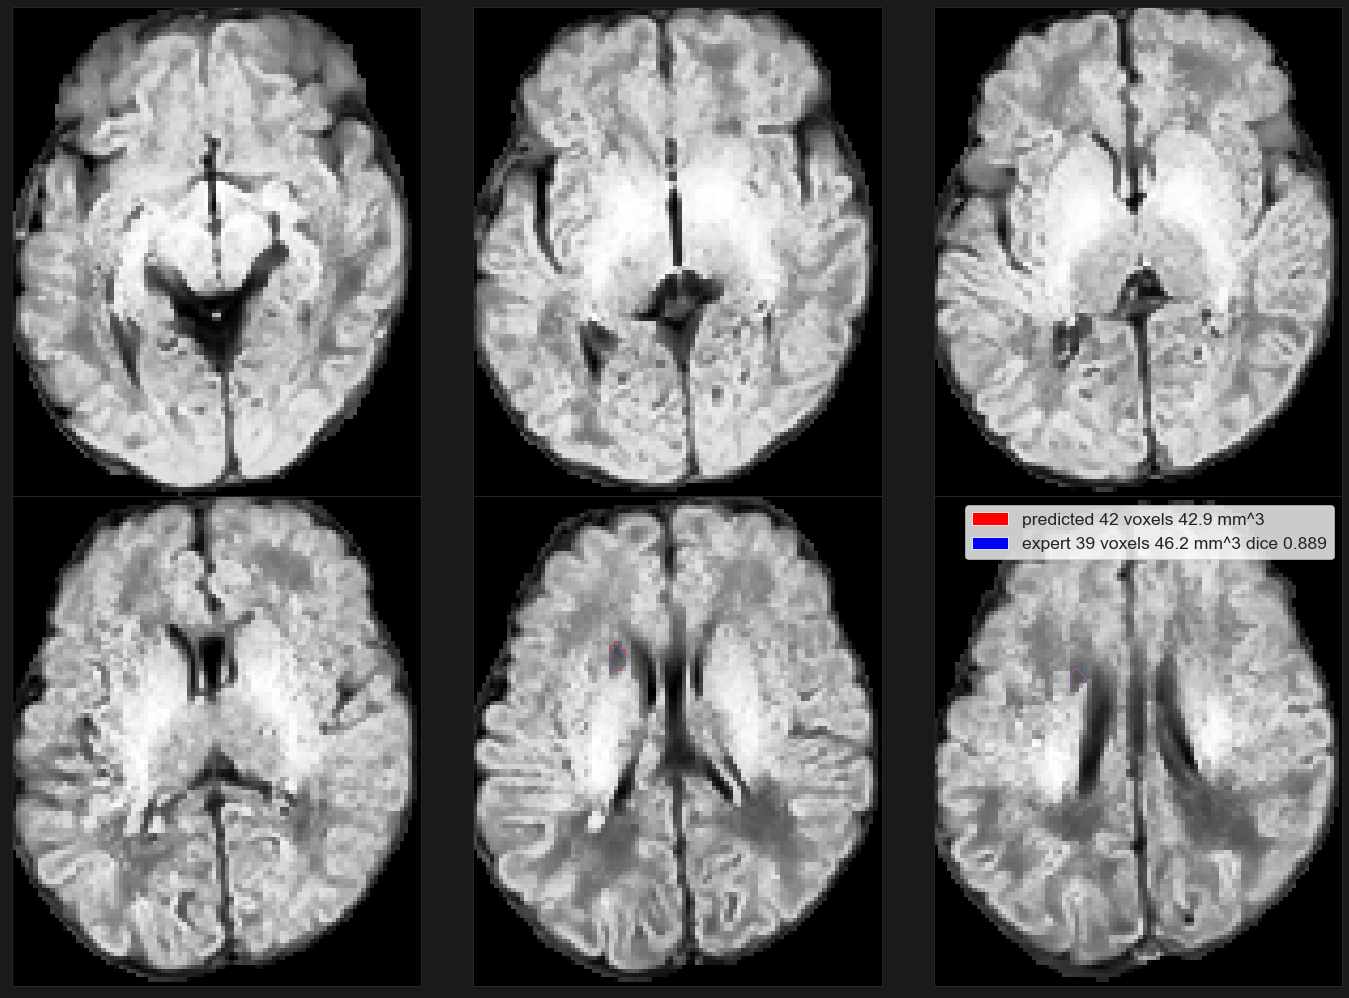

In [22]:
        img, mask, label = predict_brain(test, 9, net, 64)    
        spacing= np.prod(ants.get_spacing(ants.image_read(match_id_dict[test.iloc[0, :].patient])))
        t2f = img
        t2f_mask1 = (mask > 0.5).cpu()
        t2f_mask2 = label.cpu()
       
        ncol, nrow = 2, 3
        fig = plt.figure(figsize=((ncol-0.4)*12, (nrow+0.4)*4), facecolor='k')
        gs = gridspec.GridSpec(ncol, nrow, wspace=0, hspace=0, top=1, bottom=0, left=0, right=1)
        n = 8
        for i in range(ncol):
            for j in range(nrow):
                ax = plt.subplot(gs[i, j])
                ax.set_aspect("equal") # default equal
                ax.imshow(np.rot90(t2f[:, :, n])[:, ::-1], interpolation='nearest', cmap=plt.cm.gray)
                contours0 = measure.find_contours(np.rot90(t2f_mask1[:, :, n]==1)[:, ::-1], 0.8)
                for _, contour in enumerate(contours0):
                    ax.plot(contour[:, 1], contour[:, 0], linewidth=1.5, color='r')

                contours2 = measure.find_contours(np.rot90(t2f_mask2[:, :, n]==1)[:,::-1], 0.8)
                for _, contour in enumerate(contours2):
                    ax.plot(contour[:, 1], contour[:, 0], linewidth=1, color='b')
                modify_axis(ax)
                n += 1
        p_v = Rectangle((1, 1), 1.5, 1.5, fc="red")
        p_h = Rectangle((1, 1), 1.5, 1.5, fc="blue")
        v1 = (t2f_mask1>0).sum()
        v2 = (t2f_mask2>0).sum()
        dice = 2.0 * (t2f_mask1 * t2f_mask2).sum().float() / (v1+v2)
        print(dice, (t2f_mask1*t2f_mask2).sum(),v1, v2, v1+v2)
        plt.legend([p_v, p_h], ["predicted %s voxels %s mm^3" % (v1.item(), round(spacing*v2.item(),1)),
                                "expert %s voxels %s mm^3 dice %s" % (v2.item(), round(spacing*v1.item(),1),
                                                                      round(dice.item(), 3))],
                  loc='upper right', bbox_to_anchor=(1, 1))

## Apply to all isotropic resampled images (Figure 6)

In [31]:
template = ants.image_read('results/template/8weeks_t2f.nii.gz')

In [32]:
from segment_net_main import estimate_2d_patch
vsall = np.zeros(template.shape)
predall = np.zeros(template.shape)

total = 0
for i in meta.loc[meta.Leukomalacia == 1,:].iloc[:, 0].values:
    vs = []
    img = ants.image_read(f'results/processed/{i}_t2f_processed.nii.gz')    
    for z in range(img.shape[2]):
        prediction_z = predict_numpy_brain(img.numpy()[:, :, z:(z+1)], net)
        vs.append(prediction_z)
    vs = np.concatenate(vs, axis=2) 
    predall += vs
    vs = (vs>0.5).astype(int)
    vsall += vs
    total += 1

In [33]:
predimg = ants.make_image(vs.shape, voxval=predall/total,
                       origin=ants.get_origin(template),
                       direction=ants.get_direction(template),
                       spacing=ants.get_spacing(template))
vsimg = ants.make_image(vs.shape, voxval=vsall/total,
                       origin=ants.get_origin(template),
                       direction=ants.get_direction(template),
                       spacing=ants.get_spacing(template))

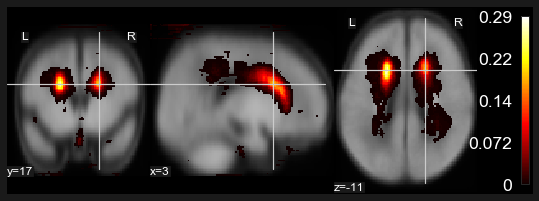

In [39]:
from nilearn import plotting
from nilearn.plotting.cm import _cmap_d as nilearn_cmaps

plotting.plot_stat_map(ants.convert_nibabel.to_nibabel(vsimg), 
                       bg_img=ants.convert_nibabel.to_nibabel(template))
#plt.savefig('results/Fig5_prediction.pdf')

In [40]:
template_t2 = ants.image_read('results/template/8weeks_t2.nii.gz')
template_pub = ants.image_read('/data1/qinqian/MRI/data/Atlas/jhu_atlas_neonate/JHU_neonate_SS_T2.img')
atlas = ants.image_read('/data1/qinqian/MRI/data/Atlas/jhu_atlas_neonate/JHU_neonate_SS_122parcellation.hdr')
annnotation = pd.read_csv('/data1/qinqian/MRI/data/Atlas/jhu_atlas_neonate/label_JHU-neonate-SS_seg.csv', header=None, index_col=0)
annnotation.head()
trans = ants.registration(template_t2, template_pub, type_of_transform='Affine')
local_atlas = ants.apply_transforms(template_t2, atlas, transformlist=trans['fwdtransforms'])

In [42]:
annotated_results = []
mask_unions = vsimg
for i in range(1, 123):
    annotated_results.append(annnotation.loc[i, :].tolist()+[mask_unions.numpy()[(local_atlas.numpy()==i)].min(),
          mask_unions.numpy()[(local_atlas.numpy()==i)].max(), 
          mask_unions.numpy()[(local_atlas.numpy()==i)].mean(),
          mask_unions.numpy()[(local_atlas.numpy()==i)].std(),
         (mask_unions.numpy()[(local_atlas.numpy()==i)]>0).sum(),
         (local_atlas.numpy()==i).sum()])
annotated_results = pd.DataFrame(annotated_results, columns=['ROI', 'Left_Right', "Tissue", "Min", "Max", "Mean", "Std", "LesionVolume", "TotalVolume"])
annotated_results.sort_values('Mean', ascending=False).head(30)

,ROI,Left_Right,Tissue,Min,Max,Mean,Std,LesionVolume,TotalVolume
22,tapetum,left,wm,0.0,0.251429,0.060743,0.059284,344,392
23,tapetum,right,wm,0.0,0.062857,0.015143,0.015017,330,400
0,corpus callosum,left,wm,0.0,0.277143,0.012892,0.045748,374,2249
110,cuneus,left,gm,0.0,0.260000,0.011811,0.036684,426,2197
111,cuneus,right,gm,0.0,0.171429,0.010850,0.031522,285,1907
12,posterior corona radiata,left,wm,0.0,0.034286,0.008304,0.007290,276,320
1,corpus callosum,right,wm,0.0,0.154286,0.007919,0.021260,749,2607
11,superior corona radiata,right,wm,0.0,0.022857,0.006376,0.005064,1102,1296
13,posterior corona radiata,right,wm,0.0,0.022857,0.006352,0.004984,292,354
28,posterior thalamic radiation,left,wm,0.0,0.100000,0.005146,0.010170,492,1060


In [43]:
annotated_results.sort_values('Mean', ascending=False).to_csv('Table5.csv')